# Лабораторная работа 2. Два класса алгоритмов сортировки

**Опора:** лекции 3–5.

Реализуются **четыре сортировки**:

- пузырьковая — обязательно;
- сортировка подсчётом — обязательно;
- одна из трёх сортировок сравнением: быстрая, слиянием, пирамидальная;
- одна из двух сортировок без сравнений: поразрядная, блочная.

Задача у всех одна: **вход** — список чисел, **выход** — тот же список,
упорядоченный по неубыванию.

Нужно самостоятельно реализовать выбранные алгоритмы, не заменяя их вызовами
готовых сортировок. Конкретный вариант реализации выбирает студент.

In [54]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

Режим: быстрый | размеры массивов: [16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 400, 416, 432, 448, 464, 480, 496, 512]


## Задача 1. Пузырьковая сортировка (обязательно)

Соседние элементы сравниваются и переставляются, пока массив не станет
упорядоченным.

Если полный проход не выполнил ни одного обмена, алгоритм должен завершиться.

In [55]:
def bubble_sort(arr):
    """Пузырьковая сортировка."""
    # TODO: реализовать
    for i in range (len(arr)):
        counter = 0 
        for j in range(0, len(arr) - i - 1):
            if arr[j] > arr[j + 1]:
                counter += 1
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
        if counter == 0:
            break
    return arr
    raise NotImplementedError("bubble_sort")

In [56]:
lk.check_sort(bubble_sort, "Пузырьковая сортировка")
lk.check_early_exit(bubble_sort, "Досрочный выход")

Пузырьковая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

## Задача 2. Сортировка подсчётом (обязательно)

Подсчитывается, сколько раз встречается каждый ключ, после чего элементы
раскладываются по местам.

- **Вход:** неотрицательные целые числа.

In [57]:
def counting_sort(arr):
    """Сортировка подсчётом для неотрицательных целых чисел."""
    # TODO: реализовать
    if len(arr) == 0:
        return []
    Max = max(arr)
    new_list = [0 for i in range(Max + 1)]
    for number in arr:
        new_list[number] += 1
    answer = []
    for num in range(len(new_list)):
        for i in range(new_list[num]):
            answer.append(num)
    return answer
    raise NotImplementedError("counting_sort")

In [58]:
lk.check_sort(counting_sort, "Сортировка подсчётом")

Сортировка подсчётом
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 100

## Выбор 1. Сортировка сравнением

Реализовать **одну** из трёх: быструю, слиянием или пирамидальную.

**Быстрая сортировка.** Разделение по опорному элементу. Способ выбора
опорного элемента определяет студент.

**Сортировка слиянием.** Разделение пополам и слияние упорядоченных частей.

**Пирамидальная сортировка.** Реализацию разделить на три функции:

- `_sift_down(arr, start, size)` восстанавливает свойство max-heap в поддереве;
- `_build_max_heap(arr)` строит max-heap снизу вверх;
- `heap_sort(arr)` сначала строит кучу, затем последовательно извлекает максимум.

In [59]:
def quick_sort(arr):
    """Быстрая сортировка."""
    # TODO: реализовать, если выбрана быстрая сортировка
    if len(arr) <= 1:
        return arr
    pivot = arr[-1]
    left = [num for num in arr if num < pivot]
    middle = [num for num in arr if num == pivot]
    right = [num for num in arr if num > pivot]
    return quick_sort(left) + middle + quick_sort(right)
    raise NotImplementedError("quick_sort")

In [60]:
lk.check_sort(quick_sort, "Быстрая сортировка", optional=True)

Быстрая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1000,

In [61]:
def merge_sort(arr):
    """Сортировка слиянием."""
    # TODO: реализовать, если выбрана сортировка слиянием
    raise NotImplementedError("merge_sort")

In [62]:
lk.check_sort(merge_sort, "Сортировка слиянием", optional=True)

Сортировка слиянием: вариант не выбран, тесты пропущены


In [63]:
def _sift_down(arr, start, size):
    """Восстановить свойство max-heap в поддереве с корнем start."""
    # TODO: реализовать просеивание вниз
    raise NotImplementedError("_sift_down")


def _build_max_heap(arr):
    """Построить max-heap снизу вверх."""
    # TODO: реализовать построение кучи
    raise NotImplementedError("_build_max_heap")


def heap_sort(arr):
    """Пирамидальная сортировка с предварительным построением max-heap."""
    # TODO: построить кучу и последовательно извлечь максимумы
    raise NotImplementedError("heap_sort")

In [64]:
lk.check_sort(heap_sort, "Пирамидальная сортировка", optional=True)

Пирамидальная сортировка: вариант не выбран, тесты пропущены


## Выбор 2. Сортировка без сравнений

Реализовать **одну** из двух.

**Поразрядная сортировка.** Обработка чисел по разрядам. Конкретную схему
выбирает студент; результат должен быть упорядочен по неубыванию.

- **Вход:** неотрицательные целые числа.

In [65]:
def radix_sort(arr):
    """Поразрядная сортировка для неотрицательных целых чисел."""
    # TODO: реализовать, если выбрана поразрядная сортировка
    raise NotImplementedError("radix_sort")

In [66]:
lk.check_sort(radix_sort, "Поразрядная сортировка", optional=True)

Поразрядная сортировка: вариант не выбран, тесты пропущены


**Блочная сортировка.** Значения распределяются по блокам, каждый блок
сортируется отдельно, после чего блоки соединяются по порядку.

- **Вход:** вещественные числа из полуинтервала `[0, 1)`.

In [68]:
def bucket_sort(arr):
    """Блочная сортировка вещественных чисел из [0, 1)."""
    # TODO: реализовать, если выбрана блочная сортировка
    if len(arr) == 0:
        return arr
    buckets = [[] for i in range(len(arr))]
    for num in arr:
        index = int(num * len(arr))
        buckets[index].append(num)
    for bucket in buckets:
        bubble_sort(bucket)
    answer = []
    for bucket in buckets:
        answer.extend(bucket)
    return answer
    raise NotImplementedError("bucket_sort")

In [69]:
lk.check_sort(bucket_sort, "Блочная сортировка", floats=True, optional=True)

Блочная сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [0.5]
    Output: [0.5]
    Expected: [0.5]
  [ok]   два элемента наоборот
    Input: [0.9, 0.1]
    Output: [0.1, 0.9]
    Expected: [0.1, 0.9]
  [ok]   уже отсортирован
    Input: [0.1, 0.2, 0.3]
    Output: [0.1, 0.2, 0.3]
    Expected: [0.1, 0.2, 0.3]
  [ok]   повторяющиеся значения
    Input: [0.3, 0.1, 0.3, 0.1]
    Output: [0.1, 0.1, 0.3, 0.3]
    Expected: [0.1, 0.1, 0.3, 0.3]
  [ok]   значения у краёв
    Input: [0.0, 0.999, 0.001, 0.5]
    Output: [0.0, 0.001, 0.5, 0.999]
    Expected: [0.0, 0.001, 0.5, 0.999]
  [ok]   узкая полоса
    Input: [0.011, 0.01, 0.012, 0.0105]
    Output: [0.01, 0.0105, 0.011, 0.012]
    Expected: [0.01, 0.0105, 0.011, 0.012]
  [ok]   100 случайных массивов
  [ok]   встроенная sorted не используется
  [ok]   метод list.sort не используется
  [ok]   модуль heapq не используется
  Пройдено 11 из 11


## Набор реализованных сортировок

Дальше всё считается по тем реализациям, которые действительно написаны.

In [70]:
INT_SORTS = lk.implemented_sorts({
    "пузырьковая": bubble_sort,
    "подсчётом": counting_sort,
    "быстрая": quick_sort,
    "слиянием": merge_sort,
    "пирамидальная": heap_sort,
    "поразрядная": radix_sort,
})
FLOAT_SORTS = lk.implemented_sorts({"блочная": bucket_sort}, floats=True)

print("В экспериментах участвуют:", ", ".join([*INT_SORTS, *FLOAT_SORTS]))

В экспериментах участвуют: пузырьковая, подсчётом, быстрая, блочная


In [71]:
sorting = lk.sorting_table(
    INT_SORTS, FLOAT_SORTS, samples=5, repeats=5,
)

Размер входа: все метрики:   0%|          | 0/640 [00:00<?, ?опыт/s]

## Эксперимент 1. Все сортировки вместе

Случайный вход одного и того же набора значений для всех сортировок.

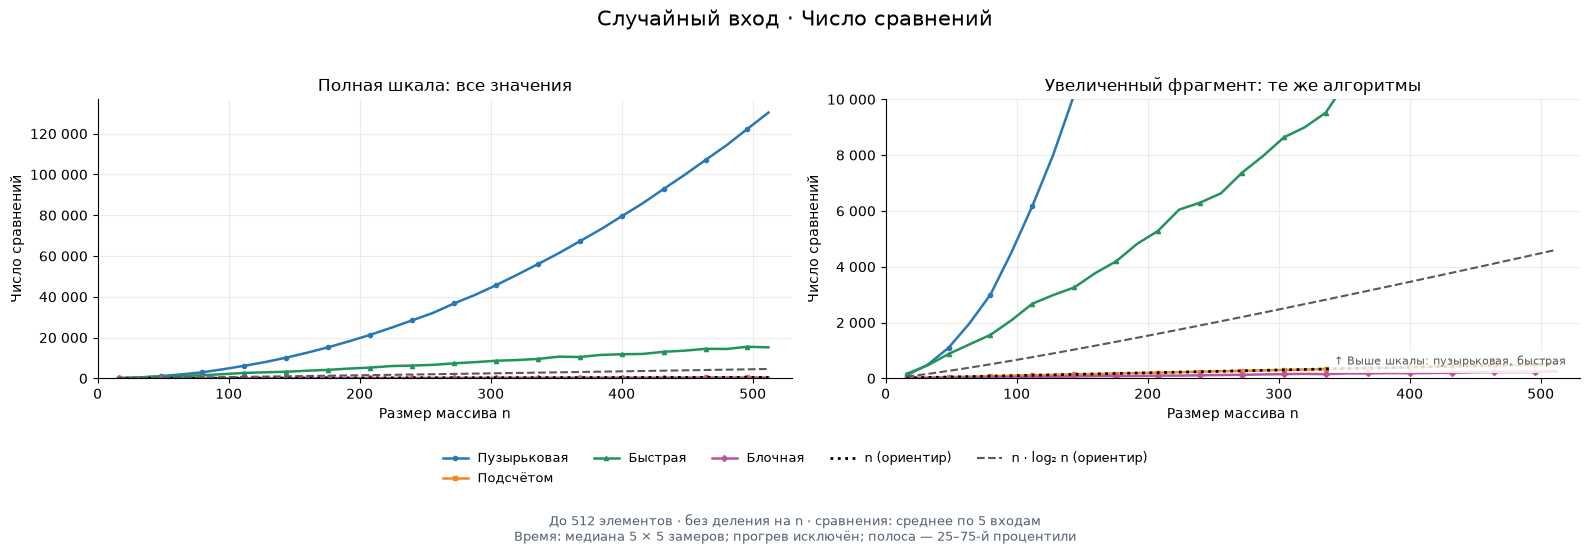

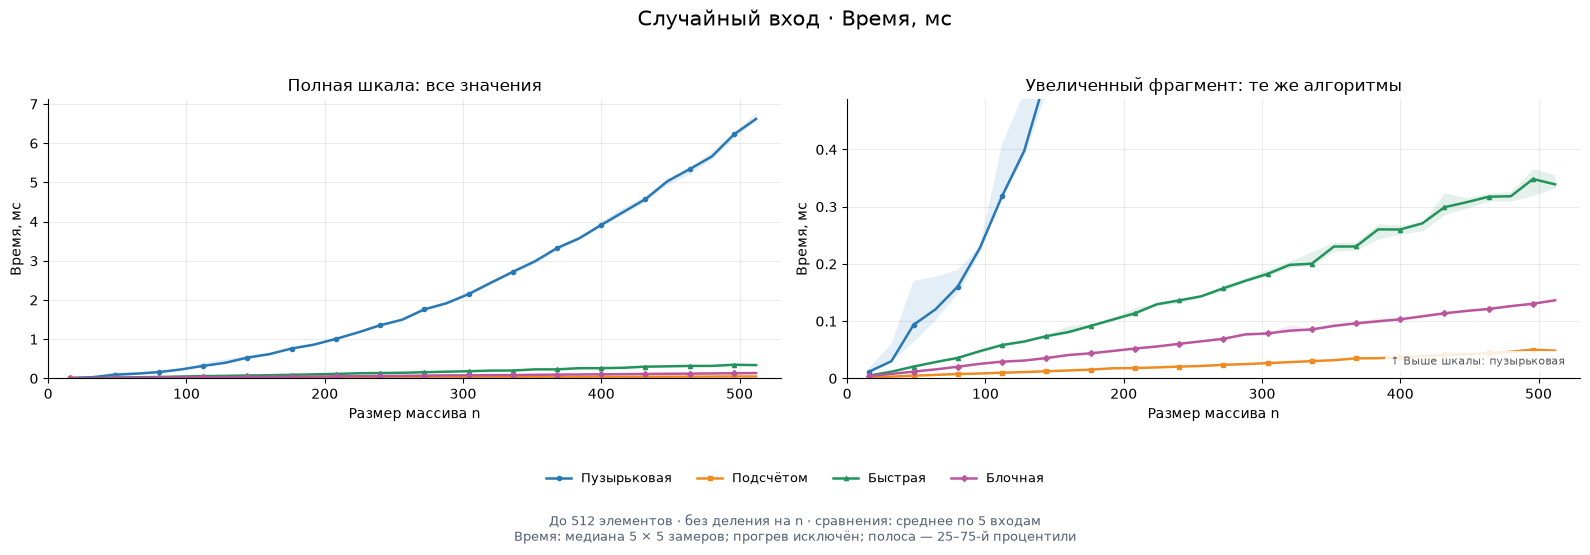

In [72]:
lk.plot_overview(sorting);

## Эксперимент 2. Пространство ключей

Размер массива зафиксирован: `n = 512`. Меняется размер пространства ключей
`k`: элементы случайно выбираются из полуинтервала `[0, k)`. В каждый вход
добавляется ключ `k - 1`, поэтому фактический диапазон не сужается случайно.
Блочная сортировка получает те же ключи, нормированные в диапазон `[0, 1)`.

Результаты разделены по типу алгоритмов:

- для сортировок на сравнениях верхний ряд показывает число сравнений между
  элементами, нижний — время;
- для сортировок, основанных на распределении, верхний ряд показывает число
  выполненных шагов циклов в коде алгоритма и его вспомогательных функций,
  нижний — время.

Один шаг цикла не равен одной машинной операции. Новый счётчик нужен для
сравнения формы зависимостей от `k`, а не абсолютной скорости разных
реализаций.

In [73]:
keyspace = lk.keyspace_table(
    INT_SORTS, FLOAT_SORTS, n=512, samples=5, repeats=5,
)

Пространство ключей: время и работа:   0%|          | 0/260 [00:00<?, ?опыт/s]

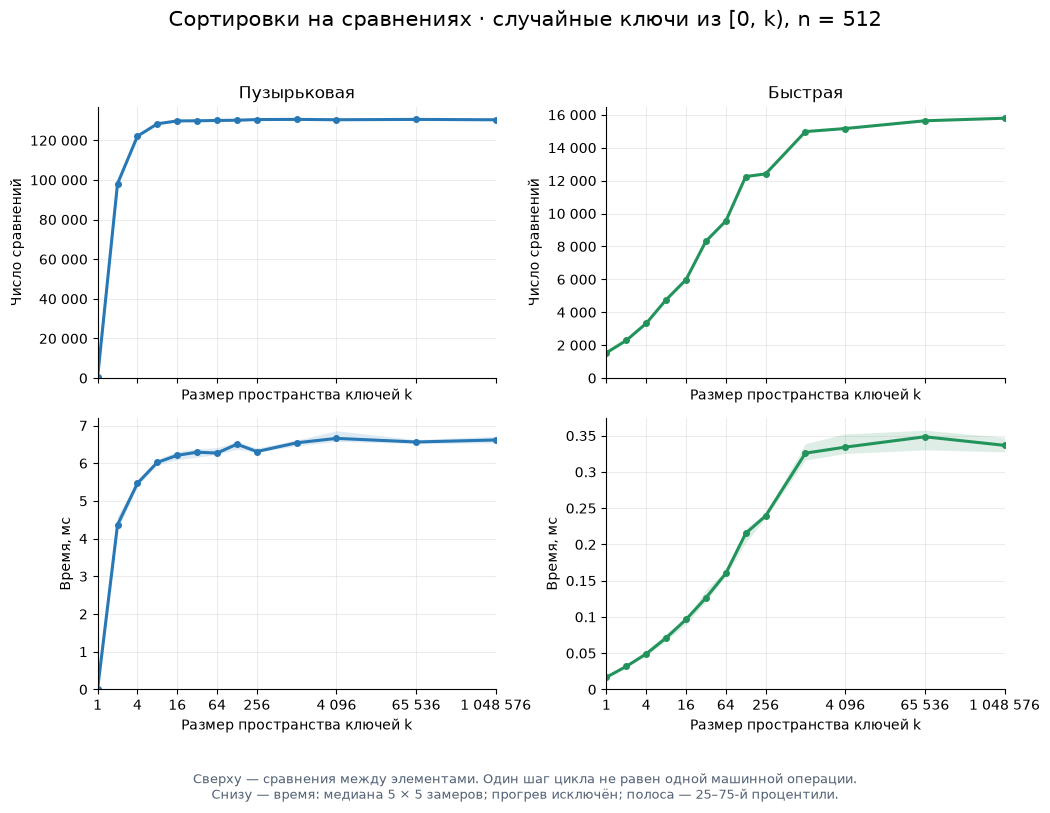

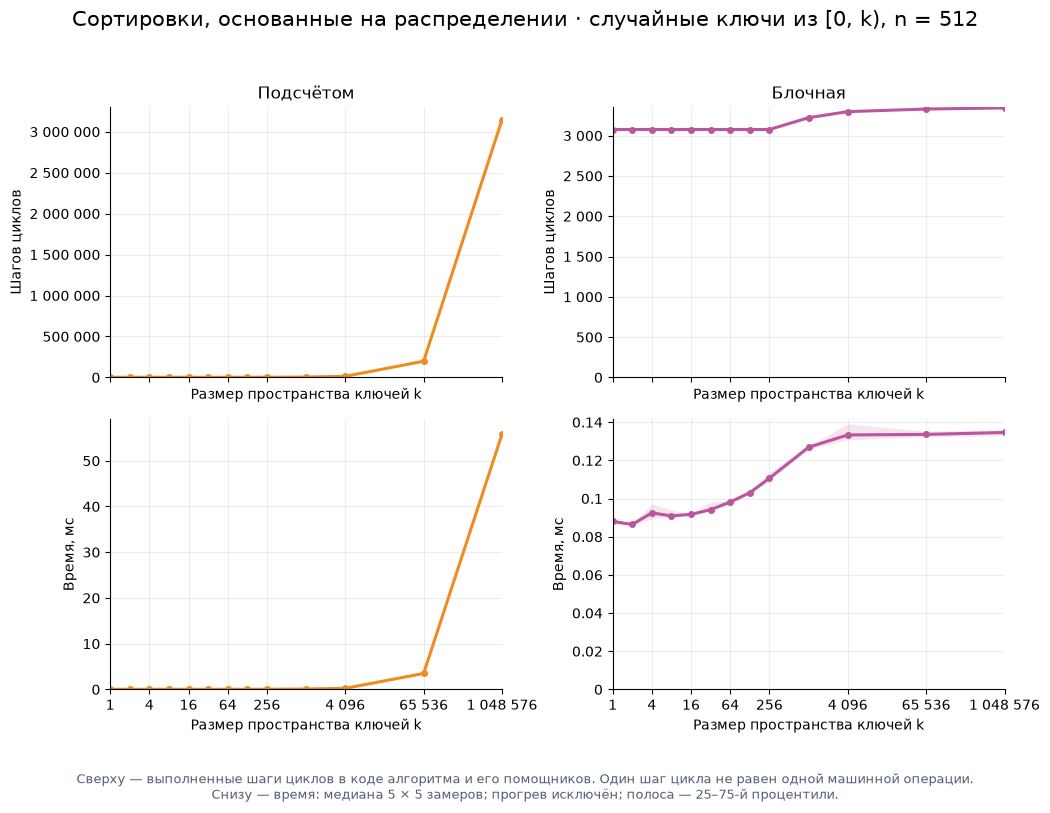

In [74]:
lk.plot_keyspace(keyspace);

## Самостоятельные выводы

Сформулируйте выводы по своим графикам и объясните их устройством реализаций.

1. Почему при увеличении `n` пузырьковая сортировка начинает заметно уступать
   выбранной сортировке сравнением? Какие части алгоритмов определяют форму их
   кривых?
2. Почему сортировки подсчётом, поразрядная и блочная могут обходиться без
   `n log n` сравнений? Какие ограничения на входные данные позволяют им это
   делать?
3. Что особенного происходит при `k = 1`, когда все элементы равны? Какие
   алгоритмы могут завершать отдельные этапы раньше, а какие продолжают
   выполнять почти всю предусмотренную работу?
4. Как повторяющиеся ключи влияют на выбранную сортировку сравнением: на обмены
   пузырьковой сортировки, разбиение быстрой сортировки, слияние или
   восстановление кучи?
5. Если выбрана поразрядная сортировка, почему изменение времени связано с
   числом разрядов? Если выбрана блочная — как распределение элементов по
   блокам влияет на стоимость внутренней сортировки?
6. Какие различия на графиках следуют из общей идеи алгоритма, а какие могут
   измениться при другом выборе опорного элемента, условии досрочного выхода
   или способе сортировки блоков?

1. Пузырьоквая сортировка многократно проходит по массиву и сравнивает соседние элементы, поэтому при увелечении количества элементов число сравнений и обменов тоже растет. То есть сложность n^2. Быстрая сортировка разделяет массив на части относительно опорного элемента, а потом рекурсивно их сортирует, поэтому справляется быстрее чем пузырьковая сортировка. Сложность можно посчитать по n log n. n^2 растет гораздо сильнее чем n log n.
2. Эти виды сортировок обходяться без сравнения элементов между собой на прямую, вместо этого они используют особенности входных данных. Сортировка подсчетом может работать только с целыми числами, заданными в не сильно большом диапозоне. Поразрядная сортировка может работать с числами которые имеют конечное количество разрядов. Для блочной сортировки числа должны иметь известный диапозон.
3. В таком случае массив уже будет осортирован, поэтому некоторые алгоритмы могут это сразу заметить и завершить свою работу раньше, чем остальные, например пузырьковая или быстрая. Сортировка подсчетом все равно посчитает все элементы, но справится быстрее чем в среднем. А например поразрядная сортировка все равно будет сраввнивать разряды всех чисел.
4. Для пузырьковой: количество обменов умеьшается. Для быстрой: одинаковые значения будут обрабатываться эффективнее. Для сортировки слиянием: практически ничего не меняется. Для пирамидальной: в целом структура алгоритма сохраняется
5. Чем равномернее будут распределены элементы по блокам, тем быстрее пройдет внутрення сортировка внутри этих блоков.
6. Для быстрой сортировки важен выбор опорного элемента, от этого зависит дальнеейше разбиение массива. Для блочной сортировки важно распределение элементов массива по блокам и способ сортировки массивов внутри блоков. Пузырьковая сортировка быстрее завершает работу есои сразу видит отсортированный массив. Общая форма графиков для каждого аглоритма определяется его сложностью